# Phase 5 - Super-Clustering Contextual (Transformer v2+)

Mejora del notebook 3 con:
- entrenamiento auto-supervisado combinado: MLM + contrastivo (SimCLR),
- embedding contextual con token CLS,
- seleccion de K robusta entre semillas (separacion + estabilidad).

In [1]:
import json
import math
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score
from scipy.stats import kruskal, f_oneway

pd.set_option('display.max_columns', 260)
pd.set_option('display.width', 280)


In [2]:
# =========================
# Config
# =========================
SYMBOL = 'GBPUSD'
MODEL_TAG = 'v2plus'
SEQ_LEN = 32
SEED = 42
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15
assert abs(TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1.0) < 1e-9

# Transformer
D_MODEL = 128
N_HEAD = 8
N_LAYERS = 4
FF_DIM = 256
DROPOUT = 0.12
EMB_DIM = 64
DELTA_BINS = 24
SIGN_BINS = 3
MASK_PROB = 0.18
BATCH_SIZE = 64
EPOCHS = 60
LR = 7e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 12
LOSS_CONTRAST_W = 0.25
CONTRAST_TEMP = 0.12

# Super-clustering
K_CANDIDATES = list(range(4, 13))
KMEANS_SEEDS = [11, 42, 77]
N_INIT_KMEANS = 40
HORIZON_HOURS = 24
MIN_CLUSTER_N = 20

IN_DIR = Path('./phases/phase05_context_sequencing/output_secuenciacion_GBPUSD_v2')
WINDOWS_PATH = IN_DIR / 'GBPUSD_sequence_windows_full_len32.parquet'
VOCAB_PATH = IN_DIR / 'GBPUSD_token_vocabulary.json'
PRICE_PATH = Path('./data/Dataset_H1_v1/parquet_h1/GBPUSD.parquet')

PREV_SUMMARY_PATH = Path('./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v2/GBPUSD_superclustering_summary.json')

OUT_DIR = Path('./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v2plus')
OUT_DIR.mkdir(parents=True, exist_ok=True)

HISTORY_CSV = OUT_DIR / 'GBPUSD_transformer_context_train_history_v2plus.csv'
ENCODER_PT = OUT_DIR / 'GBPUSD_transformer_context_encoder_v2plus.pt'
MODEL_SELECTION_CSV = OUT_DIR / 'GBPUSD_superclustering_model_selection_v2plus.csv'
EMB_PQ = OUT_DIR / 'GBPUSD_context_window_embeddings_v2plus.parquet'
EMB_CSV = OUT_DIR / 'GBPUSD_context_window_embeddings_v2plus.csv'
PROFILE_CSV = OUT_DIR / 'GBPUSD_context_regime_profile_v2plus.csv'
TRANS_CSV = OUT_DIR / 'GBPUSD_context_regime_transition_matrix_v2plus.csv'
SUMMARY_JSON = OUT_DIR / 'GBPUSD_superclustering_summary_v2plus.json'

print('WINDOWS_PATH =', WINDOWS_PATH)
print('DEVICE =', DEVICE)
print('OUT_DIR =', OUT_DIR)


WINDOWS_PATH = ./phases/phase05_context_sequencing/output_secuenciacion_GBPUSD_v2/GBPUSD_sequence_windows_full_len32.parquet
DEVICE = cuda
OUT_DIR = ./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v2plus


In [3]:
# =========================
# Reproducibilidad + helpers
# =========================
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

def pip_size(symbol: str) -> float:
    return 0.01 if str(symbol).upper().endswith('JPY') else 0.0001

def temporal_split(n: int, train_ratio: float, val_ratio: float):
    tr_end = int(n * train_ratio)
    va_end = int(n * (train_ratio + val_ratio))
    tr_end = max(1, min(tr_end, n - 2))
    va_end = max(tr_end + 1, min(va_end, n - 1))
    idx_train = np.arange(0, tr_end)
    idx_val = np.arange(tr_end, va_end)
    idx_test = np.arange(va_end, n)
    return idx_train, idx_val, idx_test

def delta_to_bins(delta_arr: np.ndarray, delta_max: float, n_bins: int):
    x = np.asarray(delta_arr, dtype=float)
    x = np.clip(x, 0.0, max(1e-6, float(delta_max)))
    z = np.log1p(x) / np.log1p(max(1e-6, float(delta_max)))
    b = np.floor(z * (n_bins - 1 + 1e-12)).astype(int)
    b = np.clip(b, 0, n_bins - 1)
    return b

def compute_forward_pips(df_price: pd.DataFrame, ts_vec: pd.Series, symbol: str, horizon_hours: int = 24):
    idx = df_price['timestamp'].to_numpy(dtype='datetime64[ns]')
    close = df_price['close'].to_numpy(dtype=float)
    ts = pd.to_datetime(ts_vec, errors='coerce').to_numpy(dtype='datetime64[ns]')
    pos = np.searchsorted(idx, ts, side='left')

    out = np.full(len(ts), np.nan, dtype=float)
    ps = pip_size(symbol)
    for i in range(len(ts)):
        p0 = pos[i]
        p1 = p0 + int(horizon_hours)
        if p0 < 0 or p1 >= len(idx):
            continue
        if idx[p0] != ts[i]:
            continue
        out[i] = (close[p1] - close[p0]) / ps
    return out

def make_masked_inputs(x: torch.Tensor, vocab_size: int, mask_id: int, mask_prob: float = 0.15):
    labels = x.clone()
    prob = torch.rand_like(x.float())
    masked = prob < mask_prob
    labels[~masked] = -100

    x_in = x.clone()
    if masked.any():
        r = torch.rand_like(x.float())
        mask_pos = masked & (r < 0.8)
        rand_pos = masked & (r >= 0.8) & (r < 0.9)
        x_in[mask_pos] = mask_id
        if rand_pos.any():
            rnd = torch.randint(low=0, high=vocab_size, size=(rand_pos.sum().item(),), device=x.device)
            x_in[rand_pos] = rnd
    return x_in, labels

def nt_xent_loss(z1: torch.Tensor, z2: torch.Tensor, temperature: float = 0.1):
    if z1.shape[0] < 2:
        return torch.zeros((), device=z1.device)

    z1 = F.normalize(z1, dim=-1)
    z2 = F.normalize(z2, dim=-1)
    z = torch.cat([z1, z2], dim=0)  # [2B, D]
    sim = torch.matmul(z, z.T) / temperature

    B = z1.shape[0]
    mask = torch.eye(2 * B, device=z.device, dtype=torch.bool)
    sim = sim.masked_fill(mask, -1e9)

    pos_idx = torch.arange(2 * B, device=z.device)
    pos_idx = (pos_idx + B) % (2 * B)

    loss = F.cross_entropy(sim, pos_idx)
    return loss

def zscore_col(x: pd.Series, eps: float = 1e-9):
    m = float(x.mean())
    s = float(x.std(ddof=0))
    if not np.isfinite(s) or s < eps:
        return pd.Series(np.zeros(len(x)), index=x.index, dtype=float)
    return (x - m) / (s + eps)


In [4]:
# =========================
# Load windows
# =========================
for p in [WINDOWS_PATH, VOCAB_PATH, PRICE_PATH]:
    if not p.exists():
        raise FileNotFoundError(f'Missing file: {p}')

W = pd.read_parquet(WINDOWS_PATH).copy()
W['start_ts'] = pd.to_datetime(W['start_ts'], errors='coerce')
W['end_ts'] = pd.to_datetime(W['end_ts'], errors='coerce')
W = W.sort_values(['start_ts', 'window_id']).reset_index(drop=True)

vocab = json.loads(VOCAB_PATH.read_text())
token_to_id = {str(k): int(v) for k, v in vocab['token_to_id'].items()}
vocab_size = len(token_to_id)
mask_id = vocab_size
cls_id = vocab_size + 1

tok = np.vstack([np.array([token_to_id[str(t)] for t in row], dtype=np.int64) for row in W['token_seq']])
dlt = np.vstack([np.asarray(row, dtype=float) for row in W['delta_h_seq']])
sgn = np.vstack([np.asarray(row, dtype=int) for row in W['move_sign_seq']])
sgn = np.clip(sgn + 1, 0, 2).astype(np.int64)

if tok.shape[1] != SEQ_LEN:
    raise RuntimeError(f'Expected seq len {SEQ_LEN}, got {tok.shape[1]}')

idx_train, idx_val, idx_test = temporal_split(len(W), TRAIN_RATIO, VAL_RATIO)
split = np.array(['train'] * len(W), dtype=object)
split[idx_val] = 'val'
split[idx_test] = 'test'
W['split'] = split

delta_max = float(np.nanquantile(dlt[idx_train].reshape(-1), 0.99))
delta_max = max(1.0, delta_max)
dlt_bin = delta_to_bins(dlt, delta_max=delta_max, n_bins=DELTA_BINS).astype(np.int64)

print('windows =', len(W), '| vocab_size =', vocab_size)
print('split counts:')
print(W['split'].value_counts().to_string())
print('delta_max(train p99)=', round(delta_max, 3))


windows = 1605 | vocab_size = 9
split counts:
split
train    1123
val       241
test      241
delta_max(train p99)= 780.0


In [5]:
# =========================
# Dataset + model
# =========================
class SeqDataset(Dataset):
    def __init__(self, tok_arr, dlt_arr, sgn_arr, indices):
        idx = np.asarray(indices, dtype=int)
        self.tok = torch.from_numpy(tok_arr[idx]).long()
        self.dlt = torch.from_numpy(dlt_arr[idx]).long()
        self.sgn = torch.from_numpy(sgn_arr[idx]).long()

    def __len__(self):
        return len(self.tok)

    def __getitem__(self, i):
        return self.tok[i], self.dlt[i], self.sgn[i]


class ContextTransformerV2(nn.Module):
    def __init__(self, vocab_size, mask_id, cls_id, seq_len, d_model, n_head, n_layers, ff_dim, dropout, delta_bins, sign_bins, emb_dim):
        super().__init__()
        self.vocab_size = int(vocab_size)
        self.mask_id = int(mask_id)
        self.cls_id = int(cls_id)
        self.seq_len = int(seq_len)

        self.token_emb = nn.Embedding(vocab_size + 2, d_model)  # + mask + cls
        self.delta_emb = nn.Embedding(delta_bins, d_model)
        self.sign_emb = nn.Embedding(sign_bins, d_model)
        self.pos_emb = nn.Parameter(torch.randn(1, seq_len + 1, d_model) * 0.02)

        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_head,
            dim_feedforward=ff_dim,
            dropout=dropout,
            activation='gelu',
            batch_first=True,
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=n_layers)

        self.to_emb = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model, emb_dim),
        )
        self.mlm_head = nn.Linear(d_model, vocab_size)

    def _prepend_cls(self, tok_ids, dlt_ids, sgn_ids):
        B = tok_ids.shape[0]
        cls_tok = torch.full((B, 1), self.cls_id, device=tok_ids.device, dtype=torch.long)
        cls_dlt = torch.zeros((B, 1), device=dlt_ids.device, dtype=torch.long)
        cls_sgn = torch.ones((B, 1), device=sgn_ids.device, dtype=torch.long)

        t = torch.cat([cls_tok, tok_ids], dim=1)
        d = torch.cat([cls_dlt, dlt_ids], dim=1)
        s = torch.cat([cls_sgn, sgn_ids], dim=1)
        return t, d, s

    def forward(self, tok_ids, dlt_ids, sgn_ids):
        t, d, s = self._prepend_cls(tok_ids, dlt_ids, sgn_ids)
        h = self.token_emb(t) + self.delta_emb(d) + self.sign_emb(s)
        h = h + self.pos_emb[:, :h.shape[1], :]
        h = self.encoder(h)

        cls_h = h[:, 0, :]
        z = self.to_emb(cls_h)

        # MLM over non-CLS positions
        tok_h = h[:, 1:, :]
        logits = self.mlm_head(tok_h)
        return logits, z

    def encode(self, tok_ids, dlt_ids, sgn_ids):
        _, z = self.forward(tok_ids, dlt_ids, sgn_ids)
        return z


In [6]:
# =========================
# Train v2+ encoder (MLM + contrastive)
# =========================
pin = DEVICE == 'cuda'
train_loader = DataLoader(SeqDataset(tok, dlt_bin, sgn, idx_train), batch_size=BATCH_SIZE, shuffle=True, pin_memory=pin)
val_loader = DataLoader(SeqDataset(tok, dlt_bin, sgn, idx_val), batch_size=BATCH_SIZE, shuffle=False, pin_memory=pin)

model = ContextTransformerV2(
    vocab_size=vocab_size,
    mask_id=mask_id,
    cls_id=cls_id,
    seq_len=SEQ_LEN,
    d_model=D_MODEL,
    n_head=N_HEAD,
    n_layers=N_LAYERS,
    ff_dim=FF_DIM,
    dropout=DROPOUT,
    delta_bins=DELTA_BINS,
    sign_bins=SIGN_BINS,
    emb_dim=EMB_DIM,
).to(DEVICE)

criterion = nn.CrossEntropyLoss(ignore_index=-100)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS, eta_min=LR * 0.05)

history = []
best_val = float('inf')
best_state = None
bad = 0

for ep in range(1, EPOCHS + 1):
    model.train()
    tr_total, tr_mlm, tr_ctr = [], [], []

    for xb_tok, xb_dlt, xb_sgn in train_loader:
        xb_tok = xb_tok.to(DEVICE, non_blocking=True)
        xb_dlt = xb_dlt.to(DEVICE, non_blocking=True)
        xb_sgn = xb_sgn.to(DEVICE, non_blocking=True)

        x1, y1 = make_masked_inputs(xb_tok, vocab_size=vocab_size, mask_id=mask_id, mask_prob=MASK_PROB)
        x2, y2 = make_masked_inputs(xb_tok, vocab_size=vocab_size, mask_id=mask_id, mask_prob=MASK_PROB)

        opt.zero_grad(set_to_none=True)
        log1, z1 = model(x1, xb_dlt, xb_sgn)
        log2, z2 = model(x2, xb_dlt, xb_sgn)

        l_mlm = 0.5 * (criterion(log1.reshape(-1, vocab_size), y1.reshape(-1)) + criterion(log2.reshape(-1, vocab_size), y2.reshape(-1)))
        l_ctr = nt_xent_loss(z1, z2, temperature=CONTRAST_TEMP)
        loss = l_mlm + LOSS_CONTRAST_W * l_ctr

        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()

        tr_total.append(float(loss.detach().cpu().item()))
        tr_mlm.append(float(l_mlm.detach().cpu().item()))
        tr_ctr.append(float(l_ctr.detach().cpu().item()))

    sched.step()

    tr = float(np.mean(tr_total)) if tr_total else np.nan
    trm = float(np.mean(tr_mlm)) if tr_mlm else np.nan
    trc = float(np.mean(tr_ctr)) if tr_ctr else np.nan

    model.eval()
    va_total, va_mlm, va_ctr = [], [], []
    with torch.no_grad():
        for xb_tok, xb_dlt, xb_sgn in val_loader:
            xb_tok = xb_tok.to(DEVICE, non_blocking=True)
            xb_dlt = xb_dlt.to(DEVICE, non_blocking=True)
            xb_sgn = xb_sgn.to(DEVICE, non_blocking=True)

            x1, y1 = make_masked_inputs(xb_tok, vocab_size=vocab_size, mask_id=mask_id, mask_prob=MASK_PROB)
            x2, y2 = make_masked_inputs(xb_tok, vocab_size=vocab_size, mask_id=mask_id, mask_prob=MASK_PROB)

            log1, z1 = model(x1, xb_dlt, xb_sgn)
            log2, z2 = model(x2, xb_dlt, xb_sgn)

            l_mlm = 0.5 * (criterion(log1.reshape(-1, vocab_size), y1.reshape(-1)) + criterion(log2.reshape(-1, vocab_size), y2.reshape(-1)))
            l_ctr = nt_xent_loss(z1, z2, temperature=CONTRAST_TEMP)
            loss = l_mlm + LOSS_CONTRAST_W * l_ctr

            va_total.append(float(loss.detach().cpu().item()))
            va_mlm.append(float(l_mlm.detach().cpu().item()))
            va_ctr.append(float(l_ctr.detach().cpu().item()))

    va = float(np.mean(va_total)) if va_total else np.nan
    vam = float(np.mean(va_mlm)) if va_mlm else np.nan
    vac = float(np.mean(va_ctr)) if va_ctr else np.nan

    if np.isfinite(va) and va < best_val - 1e-6:
        best_val = va
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        bad = 0
    else:
        bad += 1

    history.append({
        'epoch': ep,
        'train_total': tr, 'train_mlm': trm, 'train_contrast': trc,
        'val_total': va, 'val_mlm': vam, 'val_contrast': vac,
        'lr': opt.param_groups[0]['lr'],
    })

    if ep == 1 or ep % 5 == 0 or ep == EPOCHS:
        print(f'ep={ep:03d} train={tr:.6f} (mlm={trm:.4f}, ctr={trc:.4f}) val={va:.6f} (mlm={vam:.4f}, ctr={vac:.4f}) lr={opt.param_groups[0]["lr"]:.6g}')

    if bad >= PATIENCE and ep >= 18:
        print(f'Early stopping at ep={ep}')
        break

if best_state is not None:
    model.load_state_dict(best_state)

torch.save({'state_dict': model.state_dict(), 'config': {
    'seq_len': SEQ_LEN, 'd_model': D_MODEL, 'n_head': N_HEAD, 'n_layers': N_LAYERS,
    'ff_dim': FF_DIM, 'dropout': DROPOUT, 'emb_dim': EMB_DIM, 'delta_bins': DELTA_BINS,
    'sign_bins': SIGN_BINS, 'vocab_size': vocab_size, 'mask_id': mask_id, 'cls_id': cls_id,
    'delta_max': delta_max, 'loss_contrast_w': LOSS_CONTRAST_W, 'contrast_temp': CONTRAST_TEMP,
}}, ENCODER_PT)

HIST = pd.DataFrame(history)
HIST.to_csv(HISTORY_CSV, index=False)

print('best_val_total =', best_val)
print('saved encoder =', ENCODER_PT)
print('saved history =', HISTORY_CSV)


ep=001 train=2.372656 (mlm=1.6340, ctr=2.9545) val=2.204948 (mlm=1.4263, ctr=3.1146) lr=0.000699544


ep=005 train=1.496242 (mlm=1.2509, ctr=0.9816) val=2.111439 (mlm=1.4587, ctr=2.6108) lr=0.00068867


ep=010 train=1.244897 (mlm=1.0632, ctr=0.7266) val=2.385847 (mlm=1.7962, ctr=2.3584) lr=0.000655453


ep=015 train=1.013012 (mlm=0.8540, ctr=0.6362) val=2.614314 (mlm=2.0279, ctr=2.3455) lr=0.000602613


Early stopping at ep=18
best_val_total = 2.0843509137630463
saved encoder = ./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v2plus/GBPUSD_transformer_context_encoder_v2plus.pt
saved history = ./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v2plus/GBPUSD_transformer_context_train_history_v2plus.csv


In [7]:
# =========================
# Infer contextual embeddings
# =========================
model.eval()

def encode_all(tok_arr, dlt_arr, sgn_arr, bs=256):
    out = []
    with torch.no_grad():
        for i in range(0, len(tok_arr), bs):
            xb_tok = torch.from_numpy(tok_arr[i:i+bs]).long().to(DEVICE)
            xb_dlt = torch.from_numpy(dlt_arr[i:i+bs]).long().to(DEVICE)
            xb_sgn = torch.from_numpy(sgn_arr[i:i+bs]).long().to(DEVICE)
            z = model.encode(xb_tok, xb_dlt, xb_sgn)
            out.append(z.detach().cpu().numpy())
    return np.vstack(out).astype(np.float32)

Z = encode_all(tok, dlt_bin, sgn)
print('Z shape =', Z.shape)


Z shape = (1605, 64)


In [8]:
# =========================
# Super-clustering robust selection
# =========================
scaler = StandardScaler()
Z_train = scaler.fit_transform(Z[idx_train])
Z_val = scaler.transform(Z[idx_val])

rows = []
for k in K_CANDIDATES:
    seed_labels = {}
    sils, chs, dbs = [], [], []

    for sd in KMEANS_SEEDS:
        km = KMeans(n_clusters=k, n_init=N_INIT_KMEANS, random_state=sd)
        km.fit(Z_train)
        lv = km.predict(Z_val)
        seed_labels[sd] = lv

        if len(np.unique(lv)) >= 2 and len(lv) > k:
            sils.append(float(silhouette_score(Z_val, lv)))
            chs.append(float(calinski_harabasz_score(Z_val, lv)))
            dbs.append(float(davies_bouldin_score(Z_val, lv)))

    # stability ARI between seeds
    aris = []
    seeds = list(seed_labels.keys())
    for i in range(len(seeds)):
        for j in range(i + 1, len(seeds)):
            aris.append(float(adjusted_rand_score(seed_labels[seeds[i]], seed_labels[seeds[j]])))

    rows.append({
        'k': int(k),
        'sil_val_mean': float(np.mean(sils)) if len(sils) else np.nan,
        'ch_val_mean': float(np.mean(chs)) if len(chs) else np.nan,
        'db_val_mean': float(np.mean(dbs)) if len(dbs) else np.nan,
        'stability_ari_mean': float(np.mean(aris)) if len(aris) else np.nan,
    })

SEL = pd.DataFrame(rows)
SEL['z_sil'] = zscore_col(SEL['sil_val_mean'])
SEL['z_ch'] = zscore_col(SEL['ch_val_mean'])
SEL['z_db'] = zscore_col(SEL['db_val_mean'])
SEL['z_ari'] = zscore_col(SEL['stability_ari_mean'])
SEL['robust_score'] = SEL['z_sil'] + 0.8 * SEL['z_ch'] - 0.8 * SEL['z_db'] + 0.6 * SEL['z_ari']
SEL = SEL.sort_values('robust_score', ascending=False).reset_index(drop=True)
SEL.to_csv(MODEL_SELECTION_CSV, index=False)

BEST_K = int(SEL.iloc[0]['k'])
print('BEST_K =', BEST_K)
display(SEL)


BEST_K = 4


,k,sil_val_mean,ch_val_mean,db_val_mean,stability_ari_mean,z_sil,z_ch,z_db,z_ari,robust_score
0,4,0.202706,46.327204,1.427824,0.963373,2.243734,2.223112,-1.633959,1.939338,6.492994
1,7,0.127661,35.749212,1.608001,0.697992,0.587760,0.595129,-0.653248,0.336543,1.788387
2,6,0.103028,34.618117,1.748903,0.862006,0.044221,0.421050,0.113686,1.327118,1.086383
3,9,0.103020,29.448975,1.792332,0.642708,0.044025,-0.374496,0.350068,0.002647,-0.534038
4,8,0.080040,28.307259,1.703898,0.594149,-0.463037,-0.550209,-0.131279,-0.290629,-0.972559
5,5,0.126914,35.438190,2.135909,0.560581,0.571281,0.547262,2.220171,-0.493367,-1.063067
6,10,0.059741,25.449909,1.666230,0.570169,-0.910969,-0.989964,-0.336309,-0.435457,-1.695167
7,12,0.050835,26.846934,1.625374,0.444530,-1.107487,-0.774957,-0.558688,-1.194267,-1.997062
8,11,0.055275,24.754901,1.843680,0.444918,-1.009528,-1.096927,0.629558,-1.191925,-3.105872


In [9]:
# =========================
# Final clustering + profiling
# =========================
idx_trainval = np.concatenate([idx_train, idx_val])
Z_trainval = scaler.fit_transform(Z[idx_trainval])
Z_all = scaler.transform(Z)

KM = KMeans(n_clusters=BEST_K, n_init=N_INIT_KMEANS, random_state=SEED)
KM.fit(Z_trainval)
reg = KM.predict(Z_all)
dist = KM.transform(Z_all).min(axis=1)

OUT = W[['window_id', 'symbol', 'start_ts', 'end_ts', 'split']].copy()
OUT['regime_id'] = reg.astype(int)
OUT['regime_dist'] = dist.astype(float)
OUT['regime_token'] = OUT['regime_id'].map(lambda x: f'r{x:02d}')

for j in range(Z.shape[1]):
    OUT[f'ctx_emb_{j:03d}'] = Z[:, j]

PX = pd.read_parquet(PRICE_PATH, columns=['timestamp', 'close']).copy()
PX['timestamp'] = pd.to_datetime(PX['timestamp'], errors='coerce')
PX['close'] = pd.to_numeric(PX['close'], errors='coerce')
PX = PX.dropna().sort_values('timestamp').drop_duplicates('timestamp', keep='last').reset_index(drop=True)

OUT['ret_fwd_24h_pips'] = compute_forward_pips(PX, OUT['end_ts'], symbol=SYMBOL, horizon_hours=HORIZON_HOURS)

test_df = OUT[OUT['split'] == 'test'].copy()
prof = (test_df.groupby('regime_id')['ret_fwd_24h_pips']
        .agg(n='count', mean_ret='mean', median_ret='median', std_ret='std')
        .reset_index())
prof['t_like'] = prof['mean_ret'] / prof['std_ret'].replace(0, np.nan)
prof = prof.sort_values('n', ascending=False).reset_index(drop=True)

groups = []
for rid, g in test_df.groupby('regime_id'):
    x = g['ret_fwd_24h_pips'].dropna().to_numpy()
    if len(x) >= MIN_CLUSTER_N:
        groups.append(x)

kw_p = np.nan
anova_p = np.nan
eta2 = np.nan
if len(groups) >= 2:
    kw_p = float(kruskal(*groups).pvalue)
    anova_p = float(f_oneway(*groups).pvalue)
    all_vals = np.concatenate(groups)
    gm = np.mean(all_vals)
    ssb = sum(len(g) * (np.mean(g) - gm) ** 2 for g in groups)
    sst = np.sum((all_vals - gm) ** 2)
    eta2 = float(ssb / sst) if sst > 0 else np.nan

tmp = OUT.sort_values('start_ts').reset_index(drop=True)
tr = pd.crosstab(tmp['regime_token'], tmp['regime_token'].shift(-1)).fillna(0)
tr_prob = tr.div(tr.sum(axis=1), axis=0).fillna(0.0)

OUT.to_parquet(EMB_PQ, index=False)
OUT.to_csv(EMB_CSV, index=False)
prof.to_csv(PROFILE_CSV, index=False)
tr_prob.to_csv(TRANS_CSV)

summary = {
    'symbol': SYMBOL,
    'model_tag': MODEL_TAG,
    'n_windows': int(len(OUT)),
    'split_counts': {k: int(v) for k, v in OUT['split'].value_counts().to_dict().items()},
    'best_k': int(BEST_K),
    'kw_pvalue_test': None if not np.isfinite(kw_p) else float(kw_p),
    'anova_pvalue_test': None if not np.isfinite(anova_p) else float(anova_p),
    'eta2_test': None if not np.isfinite(eta2) else float(eta2),
}
SUMMARY_JSON.write_text(json.dumps(summary, indent=2))

print('saved embeddings =', EMB_PQ)
print('saved profile =', PROFILE_CSV)
print('saved transitions =', TRANS_CSV)
print('BEST_K =', BEST_K, '| kw_p =', kw_p, '| eta2 =', eta2)
display(prof)


saved embeddings = ./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v2plus/GBPUSD_context_window_embeddings_v2plus.parquet
saved profile = ./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v2plus/GBPUSD_context_regime_profile_v2plus.csv
saved transitions = ./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v2plus/GBPUSD_context_regime_transition_matrix_v2plus.csv
BEST_K = 4 | kw_p = 0.10462792692042676 | eta2 = 0.015415989682052173


,regime_id,n,mean_ret,median_ret,std_ret,t_like
0,0,95,-20.880022,-24.700165,99.556066,-0.209731
1,2,70,-7.902878,2.149343,138.629901,-0.057007
2,3,66,13.193958,15.449524,98.694528,0.133685
3,1,10,10.140061,4.850626,203.246047,0.049891


In [10]:
# =========================
# Compare vs previous v2 summary
# =========================
if PREV_SUMMARY_PATH.exists():
    prev = json.loads(PREV_SUMMARY_PATH.read_text())
    curr = json.loads(SUMMARY_JSON.read_text())

    cmp = pd.DataFrame([
        {'metric': 'best_k', 'prev_v2': prev.get('best_k'), 'v2plus': curr.get('best_k')},
        {'metric': 'kw_pvalue_test', 'prev_v2': prev.get('kw_pvalue_test'), 'v2plus': curr.get('kw_pvalue_test')},
        {'metric': 'anova_pvalue_test', 'prev_v2': prev.get('anova_pvalue_test'), 'v2plus': curr.get('anova_pvalue_test')},
        {'metric': 'eta2_test', 'prev_v2': prev.get('eta2_test'), 'v2plus': curr.get('eta2_test')},
    ])
    display(cmp)
else:
    print('No previous summary found at:', PREV_SUMMARY_PATH)


,metric,prev_v2,v2plus
0,best_k,6.000000,4.000000
1,kw_pvalue_test,0.004396,0.104628
2,anova_pvalue_test,0.004857,0.170144
3,eta2_test,0.063914,0.015416


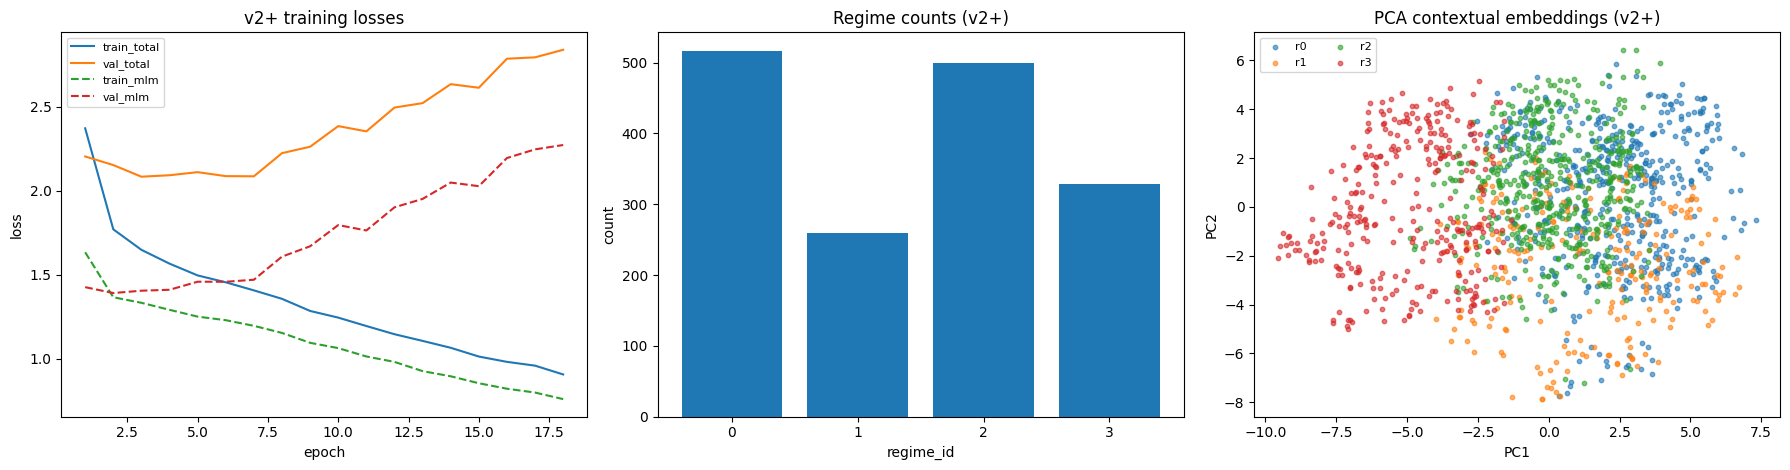

In [11]:
# =========================
# Diagnostics
# =========================
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

axes[0].plot(HIST['epoch'], HIST['train_total'], label='train_total')
axes[0].plot(HIST['epoch'], HIST['val_total'], label='val_total')
axes[0].plot(HIST['epoch'], HIST['train_mlm'], '--', label='train_mlm')
axes[0].plot(HIST['epoch'], HIST['val_mlm'], '--', label='val_mlm')
axes[0].set_title('v2+ training losses')
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('loss')
axes[0].legend(fontsize=8)

cnt = OUT['regime_id'].value_counts().sort_index()
axes[1].bar(cnt.index.astype(str), cnt.values)
axes[1].set_title('Regime counts (v2+)')
axes[1].set_xlabel('regime_id')
axes[1].set_ylabel('count')

pca = PCA(n_components=2, random_state=SEED)
xy = pca.fit_transform(Z_all)
for rid in sorted(np.unique(OUT['regime_id'])):
    m = OUT['regime_id'].to_numpy() == rid
    axes[2].scatter(xy[m, 0], xy[m, 1], s=10, alpha=0.6, label=f'r{rid}')
axes[2].set_title('PCA contextual embeddings (v2+)')
axes[2].set_xlabel('PC1')
axes[2].set_ylabel('PC2')
axes[2].legend(ncol=2, fontsize=8)

plt.tight_layout()
plt.show()


## Salidas v2+

- `GBPUSD_transformer_context_encoder_v2plus.pt`
- `GBPUSD_transformer_context_train_history_v2plus.csv`
- `GBPUSD_superclustering_model_selection_v2plus.csv`
- `GBPUSD_context_window_embeddings_v2plus.parquet`
- `GBPUSD_context_regime_profile_v2plus.csv`
- `GBPUSD_context_regime_transition_matrix_v2plus.csv`
- `GBPUSD_superclustering_summary_v2plus.json`